## Random Forest

       mfcc_1      mfcc_2      mfcc_3     mfcc_4     mfcc_5     mfcc_6  \
0 -492.671949  147.068811  -76.404904 -54.999308  -0.226016 -37.168935   
1 -450.613730  180.368273  -85.665103 -77.750988  -7.483319 -37.498395   
2 -537.986710  204.549656 -105.325511 -59.490086   3.088097 -37.844152   
3 -607.907541  226.445508 -156.033689 -21.049384  11.528269 -48.752307   
4 -612.530724  137.294089  -41.315163 -45.914490  -1.927614 -22.939446   

      mfcc_7     mfcc_8     mfcc_9    mfcc_10    mfcc_11    mfcc_12  \
0 -41.597508  -9.428412  -8.221461 -18.054654 -15.622431 -14.517657   
1 -39.846435  -0.473004  -6.796316 -28.916318 -22.095230 -14.659583   
2 -25.471458  -6.562715 -22.174805 -29.473311 -25.111846 -15.276430   
3 -14.012730 -24.005423 -25.439083 -21.761577 -32.164367 -10.539685   
4 -36.647825 -16.339434  -8.087511 -14.809998 -17.444390 -16.041396   

     mfcc_13     centroid    bandwidth   contrast       zcr label  
0 -18.351768  1753.144207  1066.922546  22.436625  0.059387 

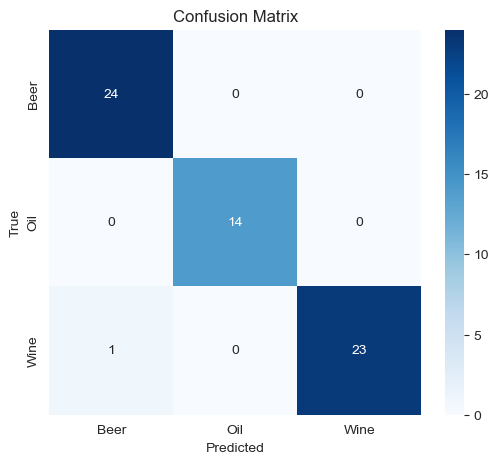

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# === 1. Load dataset ===
df = pd.read_csv("liquid_audio_features_filtered.csv")
print(df.head())

# === 2. Split features and labels ===
X = df.drop("label", axis=1).values
y = df["label"].values

# === 3. Encode labels ===
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

# === 4. Train/Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# === 5. Optional - Scale features ===
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# === 6. Train Classifier ===
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# === 7. Evaluate ===
y_pred = clf.predict(X_test)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# === 8. Confusion Matrix ===
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=le.classes_, yticklabels=le.classes_, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# === 8. Bar Plot of Classification Metrics ===
metrics = ['precision', 'recall', 'f1-score']
classes = le.classes_

# === 10. Create a DataFrame ===
# allows for easy storage and plot of classification metric data
df_metrics = pd.DataFrame(data, index=classes)

# === 11. Plot the bar chart ===
df_metrics.plot(kind='bar', figsize=(10, 6), colormap='Set2')
plt.title("Random Forest Classification Metrics by Liquid Type")
plt.xlabel("Liquid Type")
plt.xticks(rotation=0)
plt.ylabel("Score")
plt.tight_layout()
plt.legend(title="Metrics", loc='lower left')
plt.show()


## MLP

Classification Report:
              precision    recall  f1-score   support

        Beer       1.00      1.00      1.00        24
         Oil       1.00      1.00      1.00        14
        Wine       1.00      1.00      1.00        24

    accuracy                           1.00        62
   macro avg       1.00      1.00      1.00        62
weighted avg       1.00      1.00      1.00        62



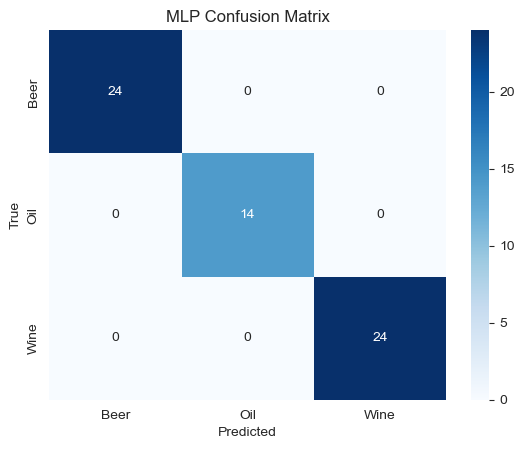

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# === 1. Load feature dataset ===
df = pd.read_csv("liquid_audio_features_filtered.csv")
X = df.drop("label", axis=1).values
y = df["label"].values

# === 2. Encode labels ===
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# === 3. Train/test split ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# === 4. Feature scaling ===
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# === 5. MLP Model ===
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),  # Can experiment with this!
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42
)

mlp.fit(X_train, y_train)

# === 6. Evaluation ===
y_pred = mlp.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=le.classes_, yticklabels=le.classes_, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("MLP Confusion Matrix")
plt.show()


## KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

# === 1. Load feature dataset ===
df = pd.read_csv("liquid_audio_features_filtered.csv")
X = df.drop("label", axis=1).values
y = df["label"].values

# === 2. Train & evaluate KNN ===
knn = KNeighborsClassifier(n_neighbors=10) 
knn.fit(X_train, y_train) # initalize the KNN model
y_pred_knn = knn.predict(X_test)

print("KNN Classification Report: ")
print(classification_report(y_test, y_pred_knn, target_names=le.classes_))

# === 3. Dot Plot ===
plt.figure(figsize=(10, 6))

# true labels displayed as dots
plt.scatter(range(len(y_test)), y_test, color='cyan', label='True', alpha=0.6)

# predicted labels as x's because our accuracy is very good :D
plt.scatter(range(len(y_pred)), y_pred, color='magenta', marker='x', label='Predicted', alpha=0.6)

plt.title("KNN Classifier - Dot Plot: Predicted vs True Labels")
plt.xlabel("Sample Index")
plt.ylabel("Liquid")
plt.legend()
plt.grid(True)
plt.yticks(ticks=range(len(le.classes_)), labels=le.classes_)  # y-axis liquid label names
plt.tight_layout()
plt.show()

## SVC

In [ ]:
import pandas as pd
import numpy as np
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# === 1. Load feature dataset ===
df = pd.read_csv("liquid_audio_features_filtered.csv")
X = df.drop("label", axis=1).values
y = df["label"].values

# === 2. Encode labels ===
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# === 3. Train/Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# === 4. Scale Features ===
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# === 5. PCA for visualization ===
# reduces to 2D so we can actually visualize the data
pca = PCA(n_components=2)
X_test_2D = pca.fit_transform(X_test)

# === 6. Train SVM on original data ===
svm = SVC(kernel='rbf', C=1, gamma='scale')
svm.fit(X_train, y_train)

# === 7. Predict and Evaluation ===
y_pred = svm.predict(X_test)

print("SVM Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# === 8. Create mesh grid for plotting decision boundary ===
h = .02  # smaller step size in the mesh grid to plot more points
x_min, x_max = X_test_2D[:, 0].min() - 1, X_test_2D[:, 0].max() + 1
y_min, y_max = X_test_2D[:, 1].min() - 1, X_test_2D[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))


# === 9. Predict the classification for each point in the mesh grid ===
Z = svm.predict(pca.inverse_transform(np.c_[xx.ravel(), yy.ravel()]))
Z = Z.reshape(xx.shape)

# === 10. Plot true and predict side-by-side with decision boundary ===
plt.figure(figsize=(12, 5))

# === 11. True labels with decision boundary ===
plt.subplot(1, 2, 1)
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
for label in np.unique(y_test):
    idxs = np.where(y_test == label)
    plt.scatter(X_test_2D[idxs, 0], X_test_2D[idxs, 1], label=le.classes_[label], alpha=0.7)
plt.title("True Labels with SVM Decision Boundary")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()

# === 12. Predicted labels with decision boundary ===
plt.subplot(1, 2, 2)
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
for label in np.unique(y_pred):
    idxs = np.where(y_pred == label)
    plt.scatter(X_test_2D[idxs, 0], X_test_2D[idxs, 1], label=le.classes_[label], alpha=0.7)
plt.title("SVM Predicted Labels with Decision Boundary")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()

plt.tight_layout()
plt.show()